# Optuna Hyperparameter Tuning vs Old Baseline

This notebook compares our Old Baseline configuration with the best parameters found by Optuna.

### Configurations
**Old Baseline:**
- `learning_rate`: 0.0001 (1e-4)
- `batch_size`: 4
- `epochs`: 20
- `architecture`: Concat_M64

**Optuna Tuned (Best Model):**
- `learning_rate`: 0.0003337
- `batch_size`: 8
- `epochs`: 30
- `architecture`: Concat_M64

,Model,Dev nDCG,Dev Top-1,Test nDCG,Test Top-1
0,Old Baseline,87.22,57.14,81.99,36.43
1,Optuna Tuned,89.34,63.75,82.32,40.00


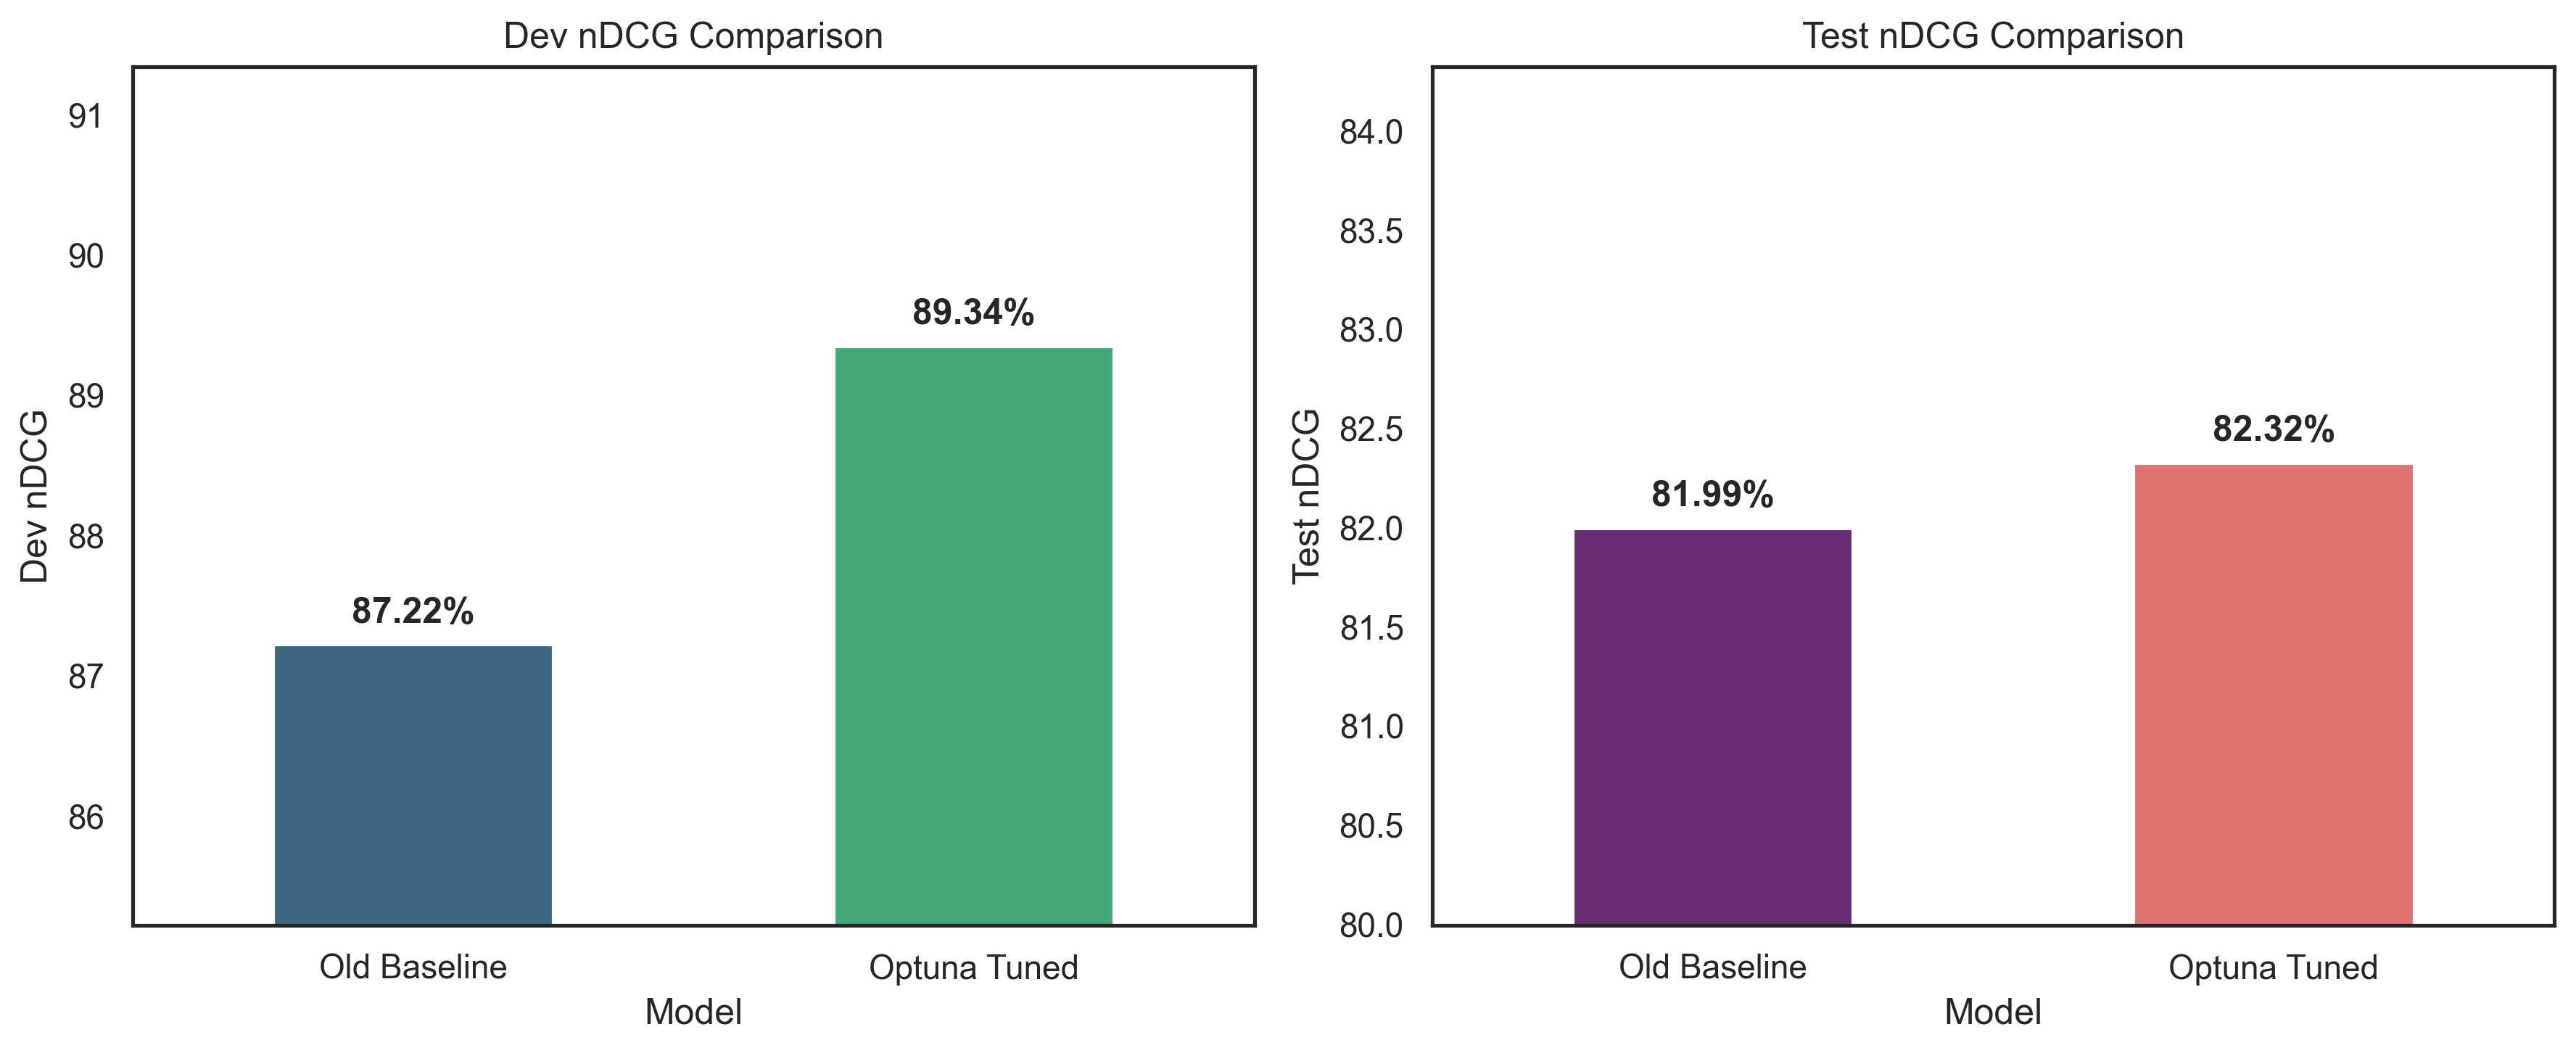

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('default')
sns.set_theme(style="white", palette="muted")
plt.rcParams['figure.dpi'] = 300

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path('..')
paths = {
    'Old Baseline': base_dir / 'fusion_ablation/concat_m64/output/summary.json',
    'Optuna Tuned': base_dir / 'hyperparam_tuning/best_model/output/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate'][0]
        
if len(data) == 2:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Model': name,
            'Dev nDCG': agg['best_dev']['ndcg'] * 100,
            'Dev Top-1': agg['best_dev']['top1'] * 100,
            'Test nDCG': agg['test']['ndcg'] * 100,
            'Test Top-1': agg['test']['top1'] * 100,
        })
        
    df = pd.DataFrame(rows)
    display(df.round(2))
    
    # Plotting
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    sns.barplot(data=df, x='Model', y='Dev nDCG', hue='Model', legend=False, palette='viridis', width=0.5, ax=ax1)
    ax1.set_ylim(max(0, df['Dev nDCG'].min() - 2), min(100, df['Dev nDCG'].max() + 2))
    ax1.set_title('Dev nDCG Comparison')
    for p in ax1.patches:
        ax1.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')
                     
    sns.barplot(data=df, x='Model', y='Test nDCG', hue='Model', legend=False, palette='magma', width=0.5, ax=ax2)
    ax2.set_ylim(max(0, df['Test nDCG'].min() - 2), min(100, df['Test nDCG'].max() + 2))
    ax2.set_title('Test nDCG Comparison')
    for p in ax2.patches:
        ax2.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')
                     
    plt.tight_layout()
    plt.show()
else:
    print("Could not load data. Make sure both baseline and optuna best model are trained.")